# Notebook 05 — Test-Set Evaluation, Baselines, and Expert Comparison




## Stage 4 results carried forward

| Arm | τ | 95% CI | Valid JSON | SSVC accuracy |
|---|---|---|---|---|
| A0 zero-shot | 0.066 | [0.013, 0.120] | 73.3% | 6.5% |
| A1 one-shot | 0.288 | [0.235, 0.341] | 95.0% | 24.7% |
| **A3 fine-tuned** | **0.647** | **[0.602, 0.689]** | **100%** | **80.6%** |

All pairwise differences significant at p < 0.001. Rank stability for A3 was 0.676.

Those numbers are on the **validation** split, which guided training decisions. This notebook
repeats the measurement on **test**, which nothing has touched.


## 1 · Install


In [1]:
%pip install -q --upgrade --no-cache-dir \
    "transformers==4.49.0" "accelerate==1.3.0" "peft==0.14.0" \
    "bitsandbytes>=0.45.2" "scipy>=1.11,<2" "pandas>=2,<3" \
    "matplotlib>=3.8" "seaborn>=0.13" "openpyxl>=3.1" "tqdm"
print("done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 92.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 206.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 377.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 217.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 178.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 137.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.6/336.6 kB 224.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.8/374.8 kB 254.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 172.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 127.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 203.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2 · Safety controls

Auto-disconnects the runtime on completion or failure so no compute is spent on an idle session.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import collections, gc, hashlib, json, math, os, platform, random, re, shutil, sys, time, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, transformers, peft
from tqdm.auto import tqdm

SEED = 42
AUTO_DISCONNECT = True

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

def kill_runtime(reason=""):
    if not AUTO_DISCONNECT:
        print(f"AUTO_DISCONNECT off. {reason}"); return
    print(f"\nDisconnecting runtime. {reason}"); time.sleep(3)
    try:
        from google.colab import runtime; runtime.unassign()
    except Exception:
        os.kill(os.getpid(), 9)

def guard(fn, *a, **kw):
    try: return fn(*a, **kw)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"\nFAILED: {type(e).__name__}: {e}")
        kill_runtime("Cell failed."); raise

print("safety controls active | AUTO_DISCONNECT =", AUTO_DISCONNECT)

safety controls active | AUTO_DISCONNECT = True


## 3 · GPU check


In [3]:
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU."
GPU_NAME = torch.cuda.get_device_name(0)
GPU_VRAM = torch.cuda.get_device_properties(0).total_memory/1024**3
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(f"GPU: {GPU_NAME} ({GPU_VRAM:.1f} GiB) | dtype {DTYPE}")

if "A100" in GPU_NAME or "H100" in GPU_NAME:
    print("\nA100/H100 detected — ~4x the cost of a T4 for this workload.")
    print("Switch to T4, or set ALLOW_EXPENSIVE_GPU = True to override.")
    ALLOW_EXPENSIVE_GPU = False
    assert ALLOW_EXPENSIVE_GPU, "Expensive GPU blocked."

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"   # must match the adapter's base model
print("base model:", MODEL_ID)

GPU: Tesla T4 (14.6 GiB) | dtype torch.bfloat16
base model: Qwen/Qwen2.5-3B-Instruct


## 4 · Load inputs

Upload three archives when prompted: the trained adapter, the training data, and the Corpus B
resource pool (needed for the rule-based baselines).


In [5]:
from google.colab import files, drive

BASE = Path("/content/mcasm_project")
DATA, POOL, RUN = BASE/"train_ready", BASE/"corpus_b", BASE/"stage5"
FIG, TAB, ADP = RUN/"figures", RUN/"tables", BASE/"adapter"
for d in (DATA, POOL, RUN, FIG, TAB, ADP): d.mkdir(parents=True, exist_ok=True)

NEEDED = {"mcasm_adapter.zip": ADP, "mcasm_train_ready.zip": DATA, "mcasm_corpus_b.zip": POOL}
missing = [n for n in NEEDED if not Path(f"/content/{n}").exists()]
if missing:
    print("Upload:", ", ".join(missing)); files.upload()

for name, dest in NEEDED.items():
    p = Path(f"/content/{name}")
    if p.exists():
        with zipfile.ZipFile(p) as z: z.extractall(dest)
        print(f"{name:28} -> {dest.name}")

try:
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage5"); DRIVE.mkdir(parents=True, exist_ok=True)
    print("Drive mirror:", DRIVE)
except Exception as e:
    DRIVE = None; print(f"Drive unavailable ({type(e).__name__})")

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name
        if src.is_dir(): shutil.copytree(src, dst, dirs_exist_ok=True)
        else: dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy(src, dst)
    except Exception as e: print(f"  mirror failed ({name}): {type(e).__name__}")

def read_jsonl(p): return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
splits = {s: read_jsonl(DATA/f"{s}.jsonl") for s in ("train","validation","test")}
MAX_SEQ = int(json.loads((DATA/"manifest_03.json").read_text())["max_seq_length"])
print(f"\ntest split: {len(splits['test'])} instances")

mcasm_adapter.zip            -> adapter
mcasm_train_ready.zip        -> train_ready
mcasm_corpus_b.zip           -> corpus_b
Mounted at /content/drive
Drive mirror: /content/drive/MyDrive/mcasm_stage5

test split: 150 instances


## 5 · Evaluation functions

Identical to Stage 4 except the grounding lookup, which is now keyed by bare finding id. The
previous version keyed by the full `id|provider|service|type` line while `why` uses the bare id,
so the join never matched and every grounding score came back `NaN`.


In [6]:
from scipy.stats import kendalltau, spearmanr

def parse_output(text, ids):
    if not text: return None
    s = text.strip()
    if "```" in s:
        p = [x for x in s.split("```") if "{" in x]
        if p: s = p[0].replace("json","",1).strip()
    a,b = s.find("{"), s.rfind("}")
    if a == -1 or b <= a: return None
    try: o = json.loads(s[a:b+1])
    except json.JSONDecodeError: return None
    if not isinstance(o, dict) or "ranking" not in o: return None
    valid, seen, rk = set(ids), set(), []
    for f in o["ranking"]:
        if isinstance(f,str) and f in valid and f not in seen: rk.append(f); seen.add(f)
    o["ranking"] = rk + [f for f in ids if f not in seen]
    o["_complete"] = len(rk) == len(ids)
    return o

def ranks_of(order, ids):
    pos = {f:i for i,f in enumerate(order)}
    return np.array([pos.get(f,len(order)) for f in ids], float)

def score(pred, gold):
    ids = list(gold); p,g = ranks_of(pred,ids), ranks_of(gold,ids)
    t,_ = kendalltau(p,g,variant="b"); r,_ = spearmanr(p,g)
    out = {"tau_b": 0. if np.isnan(t) else float(t), "spearman": 0. if np.isnan(r) else float(r)}
    rel = {f: len(gold)-i for i,f in enumerate(gold)}
    for k in (3,5):
        if len(ids) >= k:
            out[f"p@{k}"] = len(set(pred[:k]) & set(gold[:k]))/k
            dcg  = sum(rel.get(f,0)/np.log2(i+2) for i,f in enumerate(pred[:k]))
            idcg = sum(v/np.log2(i+2) for i,v in enumerate(sorted(rel.values(),reverse=True)[:k]))
            out[f"ndcg@{k}"] = dcg/idcg if idcg else 0.
    return out

def indicator_map(rec):
    """Bare finding id -> its indicator string. Keying by id is the Stage 4 fix."""
    out = {}
    for line in rec["messages"][1]["content"].split("\n"):
        if " :: " not in line: continue
        head, ind = line.split(" :: ", 1)
        out[head.split("|")[0].strip()] = ind.strip()
    return out

IND = [("internet","public"),("public","public"),("exposed","public"),
       ("unauthenticated","noauth"),("no authentication","noauth"),
       ("unencrypted","unencrypted"),("not encrypted","unencrypted"),
       ("hardcoded","secret_in_code"),("credential","secret_in_code"),("secret","secret_in_code"),
       ("cross-account","cross_account"),("wildcard","wildcard"),("admin","priv=admin"),
       ("privilege escalation","privesc"),("privesc","privesc"),("shared","shared_infra"),
       ("port","ports="),("escalation","privesc")]

def grounding(why, indicators):
    t, s = str(why).lower(), str(indicators).lower(); c = sup = 0
    for ph, ind in IND:
        if ph in t: c += 1; sup += int(ind in s)
    for p in re.findall(r"port\D{0,3}(\d{2,5})", t): c += 1; sup += int(p in s)
    return sup/c if c else np.nan     # nan = no checkable claim, not zero

def bootstrap_ci(v, clusters=None, n_boot=4000):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if not len(v): return {"point":np.nan,"lo":np.nan,"hi":np.nan,"n_units":0}
    rng = np.random.default_rng(SEED); pt = float(v.mean())
    if clusters is None:
        d = [v[rng.integers(0,len(v),len(v))].mean() for _ in range(n_boot)]; nu = len(v)
    else:
        ix = collections.defaultdict(list)
        for i,c in enumerate(clusters[:len(v)]): ix[c].append(i)
        ks = list(ix); nu = len(ks)
        d = [v[[i for j in rng.integers(0,len(ks),len(ks)) for i in ix[ks[j]]]].mean()
             for _ in range(n_boot)]
    lo,hi = np.percentile(d,[2.5,97.5])
    return {"point":pt,"lo":float(lo),"hi":float(hi),"n_units":nu}

def perm_test(a, b, n=10000):
    a,b = np.asarray(a,float), np.asarray(b,float); m = min(len(a),len(b))
    d = a[:m]-b[:m]; obs = float(d.mean()); rng = np.random.default_rng(SEED)
    null = (rng.choice([-1.,1.],(n,len(d)))*d).mean(axis=1)
    return {"mean_difference":obs, "p_value":float((np.abs(null)>=abs(obs)).mean()), "n_pairs":m}
print("evaluation functions ready (grounding key fixed)")

evaluation functions ready (grounding key fixed)


## 6 · Rule-based baselines

Three non-model comparators. B3 shares a scoring function with the gold ordering, so its near
perfect score is a wiring check rather than a result — the informative comparison is against
expert judgement in Section 9.


In [7]:
pool = {}
pf = POOL/"resource_pool.jsonl"
if pf.exists():
    for line in open(pf, encoding="utf-8"):
        r = json.loads(line); pool[r["finding_id"]] = r
print(f"resource pool: {len(pool)} findings")

SENS = {"secrets":3.,"phi":2.5,"pci":2.5,"pii":2.,"internal":1.,"none":0.}
W = {"exposure":.30,"identity":.25,"data":.20,"blast":.15,"intel":.10}
SENSITIVE_PORTS = {22,23,3389,3306,5432,6379,27017,9200,1433}

def crs(f):
    e,i,d,b = f["exposure"], f["identity"], f["data"], f["blast_radius"]
    t = f.get("threat_intel", {})
    ex = 3*e["internet_reachable"] + 2*(not e["auth_required"]) \
       + 1*bool(set(e.get("open_ports",[])) & SENSITIVE_PORTS)
    idn = 3*(i["privilege_level"]=="admin") + 1.5*(i["privilege_level"]=="write") \
        + 2*i["wildcard_actions"] + 2*i["wildcard_principals"] \
        + 1.5*i["assumable_by_external"] + .5*min(i.get("privesc_path_count",0),4)
    da = SENS.get(d["sensitivity"],0) + 1*(d["encrypted_at_rest"] is False) \
       + 2*d["public_write"] + 1*d["public_read"] + 2*d["hardcoded_secret"]
    bl = min(b["linked_resources"]/5,3) + 1.5*b["cross_account_trust"] \
       + 1*b["is_shared_infrastructure"]
    it = 3*t.get("in_kev",False) + 2*(t.get("max_epss") or 0)
    return round(W["exposure"]*ex + W["identity"]*idn + W["data"]*da
                 + W["blast"]*bl + W["intel"]*it, 4)

def b_random(ids, seed=SEED):
    r = list(ids); np.random.default_rng(seed).shuffle(r); return r

def b_alphabetical(ids):
    return sorted(ids)

def b_composite(ids):
    scored = [(crs(pool[i]) if i in pool else 0., i) for i in ids]
    scored.sort(key=lambda x: (-x[0], x[1]))
    return [i for _, i in scored]

BASELINES = {"B0_random": b_random, "B1_alphabetical": b_alphabetical, "B3_composite": b_composite}
print("baselines:", list(BASELINES))

resource pool: 340 findings
baselines: ['B0_random', 'B1_alphabetical', 'B3_composite']


In [8]:
brows = []
for name, fn in BASELINES.items():
    for rec in splits["test"]:
        ids, gold = rec["input_order"], rec["target"]["ranking"]
        brows.append({"arm": name, "instance_id": rec["instance_id"], "valid": 1,
                      **score(fn(ids), gold)})
base_df = pd.DataFrame(brows)

bsum = []
for arm, g in base_df.groupby("arm"):
    ci = bootstrap_ci(g["tau_b"].values, g["instance_id"].values)
    bsum.append({"arm":arm,"tau_b":ci["point"],"ci_lo":ci["lo"],"ci_hi":ci["hi"],
                 "spearman":g["spearman"].mean(),
                 "ndcg@5":g.get("ndcg@5",pd.Series(dtype=float)).mean(),
                 "p@3":g.get("p@3",pd.Series(dtype=float)).mean(),"n":len(g)})
baseline_summary = pd.DataFrame(bsum).sort_values("tau_b", ascending=False)
display(baseline_summary.round(4))
baseline_summary.to_csv(TAB/"baselines.csv", index=False); mirror(TAB/"baselines.csv","tables/baselines.csv")

,arm,tau_b,ci_lo,ci_hi,spearman,ndcg@5,p@3,n
2,B3_composite,0.9408,0.9307,0.9507,0.9724,0.9815,0.8733,150
1,B1_alphabetical,0.1228,0.0849,0.1632,0.1454,0.6834,0.3156,150
0,B0_random,-0.0143,-0.0502,0.0226,-0.0238,0.6140,0.2333,150


## 7 · Load the fine-tuned model

Restores the LoRA adapter from Stage 4 onto the base model. No training happens here.


In [38]:
%pip uninstall -y -q transformers tokenizers
!rm -rf /usr/local/lib/python3.12/dist-packages/transformers*
%pip install -q --no-cache-dir "transformers==4.49.0"
import transformers, importlib
print("installed:", transformers.__version__)
print("\n>>> NOW DO: Runtime > Restart session  <<<")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 64.8 MB/s eta 0:00:00
installed: 5.13.1

>>> NOW DO: Runtime > Restart session  <<<


In [9]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token_id is None: tok.pad_token = tok.eos_token

QUANT = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                           bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)

def fresh_model():
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=QUANT,
            device_map={"":0}, torch_dtype=DTYPE, attn_implementation="sdpa")
    m.config.use_cache = True
    return m

def free_gpu():
    for n in ("model","base_model"):
        if n in globals(): del globals()[n]
    gc.collect(); torch.cuda.empty_cache()

adapter_path = ADP if (ADP/"adapter_config.json").exists() else next(ADP.rglob("adapter_config.json")).parent
model = guard(lambda: PeftModel.from_pretrained(fresh_model(), adapter_path))
model.eval()
print(f"adapter loaded from {adapter_path}")
print(f"GPU used: {torch.cuda.memory_allocated()/1024**3:.1f} GiB")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

adapter loaded from /content/mcasm_project/adapter
GPU used: 2.0 GiB


## 8 · Test-set evaluation

The test split has not influenced any decision in this project. `raw` is now stored at 4000
characters so the qualitative example can be reconstructed.


In [10]:
GEN_BATCH = 8 if GPU_VRAM >= 20 else 4
GEN_CAP   = 722
EVAL_N, N_SHUFFLES = 60, 2

@torch.no_grad()
def generate_batch(mdl, msg_list, max_new=GEN_CAP):
    prompts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in msg_list]
    tok.padding_side = "left"
    enc = tok(prompts, return_tensors="pt", padding=True).to(mdl.device)
    out = mdl.generate(**enc, max_new_tokens=max_new, do_sample=False,
                       temperature=None, top_p=None, top_k=None,
                       pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
    tok.padding_side = "right"
    n = enc["input_ids"].shape[1]
    return [tok.decode(o[n:], skip_special_tokens=True) for o in out]

def shuffled(rec, seed):
    lines = rec["messages"][1]["content"].split("\n")
    head = [l for l in lines if "::" not in l]; body = [l for l in lines if "::" in l]
    np.random.default_rng(seed).shuffle(body)
    return [dict(rec["messages"][0]), {"role":"user","content":"\n".join(head+body)}]

def run_eval(mdl, records, arm, n_shuffles=1):
    jobs = [(r,s) for r in records for s in range(n_shuffles)]
    rows, orders = [], collections.defaultdict(list)
    bar = tqdm(total=len(jobs), desc=arm, unit="gen"); t0 = time.time()
    for i in range(0, len(jobs), GEN_BATCH):
        chunk = jobs[i:i+GEN_BATCH]
        texts = generate_batch(mdl, [r["messages"][:2] if s==0 else shuffled(r,SEED+s) for r,s in chunk])
        for (rec,s), txt in zip(chunk, texts):
            ids, gold = rec["input_order"], rec["target"]["ranking"]
            indmap = indicator_map(rec)
            o = parse_output(txt, ids)
            if o is None:
                rows.append({"arm":arm,"instance_id":rec["instance_id"],"shuffle":s,"valid":0,
                             "tau_b":0.,"spearman":0.,"ssvc_acc":np.nan,"grounding":np.nan,
                             "why_count":0,"raw":txt[:4000]})
                continue
            orders[rec["instance_id"]].append(o["ranking"])
            gt, pr = rec["target"].get("ssvc",{}), o.get("ssvc",{}) or {}
            acc = np.mean([pr.get(k)==v for k,v in gt.items()]) if gt else np.nan
            whys = o.get("why",{}) or {}
            gv = [grounding(w, indmap.get(k,"")) for k,w in whys.items() if k in indmap]
            gv = [x for x in gv if not np.isnan(x)]
            rows.append({"arm":arm,"instance_id":rec["instance_id"],"shuffle":s,"valid":1,
                         **score(o["ranking"], gold),
                         "ssvc_acc":float(acc) if acc==acc else np.nan,
                         "grounding":float(np.mean(gv)) if gv else np.nan,
                         "why_count":len(whys), "raw":json.dumps(o)[:4000]})
        done = min(i+GEN_BATCH,len(jobs)); el = time.time()-t0
        bar.update(len(chunk)); bar.set_postfix_str(f"{el/done:.1f}s/gen | ETA {(len(jobs)-done)*el/done/60:.1f}m")
    bar.close()
    df = pd.DataFrame(rows)
    if n_shuffles > 1:
        st = {}
        for iid, os_ in orders.items():
            if len(os_) < 2: continue
            pw = [kendalltau(ranks_of(os_[a],os_[0]), ranks_of(os_[b],os_[0]), variant="b")[0]
                  for a in range(len(os_)) for b in range(a+1,len(os_))]
            pw = [x for x in pw if not np.isnan(x)]
            if pw: st[iid] = float(np.mean(pw))
        df["stability"] = df["instance_id"].map(st)
    return df

test_recs = splits["test"][:EVAL_N]
n_gen = EVAL_N*N_SHUFFLES
print(f"{EVAL_N} test instances x {N_SHUFFLES} shuffles = {n_gen} generations")
print(f"ESTIMATED TIME: {n_gen*(1.4 if GPU_VRAM>=20 else 21)/60:.0f}-{n_gen*(2.2 if GPU_VRAM>=20 else 27)/60:.0f} min")

60 test instances x 2 shuffles = 120 generations
ESTIMATED TIME: 42-54 min


In [11]:
df_test = guard(run_eval, model, test_recs, "A3_test", N_SHUFFLES)
print(f"\ntau {df_test['tau_b'].mean():.3f} | valid {df_test['valid'].mean():.1%}"
      f" | stability {df_test['stability'].mean():.3f}"
      f" | grounding {df_test['grounding'].mean():.3f}"
      f" | why present {(df_test['why_count']>0).mean():.1%}")
df_test.to_csv(TAB/"eval_test.csv", index=False); mirror(TAB/"eval_test.csv","tables/eval_test.csv")

A3_test:   0%|          | 0/120 [00:00<?, ?gen/s]


tau 0.717 | valid 100.0% | stability 0.680 | grounding 0.595 | why present 100.0%


### Validation versus test — does the result hold?


In [12]:
VAL = {"tau_b":0.6470,"ci_lo":0.6023,"ci_hi":0.6892,"json_validity":1.0,
       "ssvc_acc":0.8064,"stability":0.6756}

f0 = df_test[df_test["shuffle"]==0]
ci = bootstrap_ci(f0["tau_b"].values, f0["instance_id"].values)
TEST = {"tau_b":ci["point"],"ci_lo":ci["lo"],"ci_hi":ci["hi"],
        "json_validity":f0["valid"].mean(),"ssvc_acc":f0["ssvc_acc"].mean(),
        "stability":df_test["stability"].mean()}

gen = pd.DataFrame([{"metric":k,"validation":VAL[k],"test":TEST[k],"difference":TEST[k]-VAL[k]}
                    for k in VAL])
display(gen.round(4))
gen.to_csv(TAB/"generalisation.csv", index=False); mirror(TAB/"generalisation.csv","tables/generalisation.csv")

d = abs(TEST["tau_b"]-VAL["tau_b"])
print(f"\ntau difference: {d:.4f}")
print("Result holds on unseen data." if d < 0.10 else
      "Meaningful gap — discuss overfitting to the validation split.")

,metric,validation,test,difference
0,tau_b,0.6470,0.7446,0.0976
1,ci_lo,0.6023,0.7087,0.1064
2,ci_hi,0.6892,0.7813,0.0921
3,json_validity,1.0000,1.0000,0.0000
4,ssvc_acc,0.8064,0.8037,-0.0027
5,stability,0.6756,0.6801,0.0045



tau difference: 0.0976
Result holds on unseen data.


### Figure 1 — test results against baselines


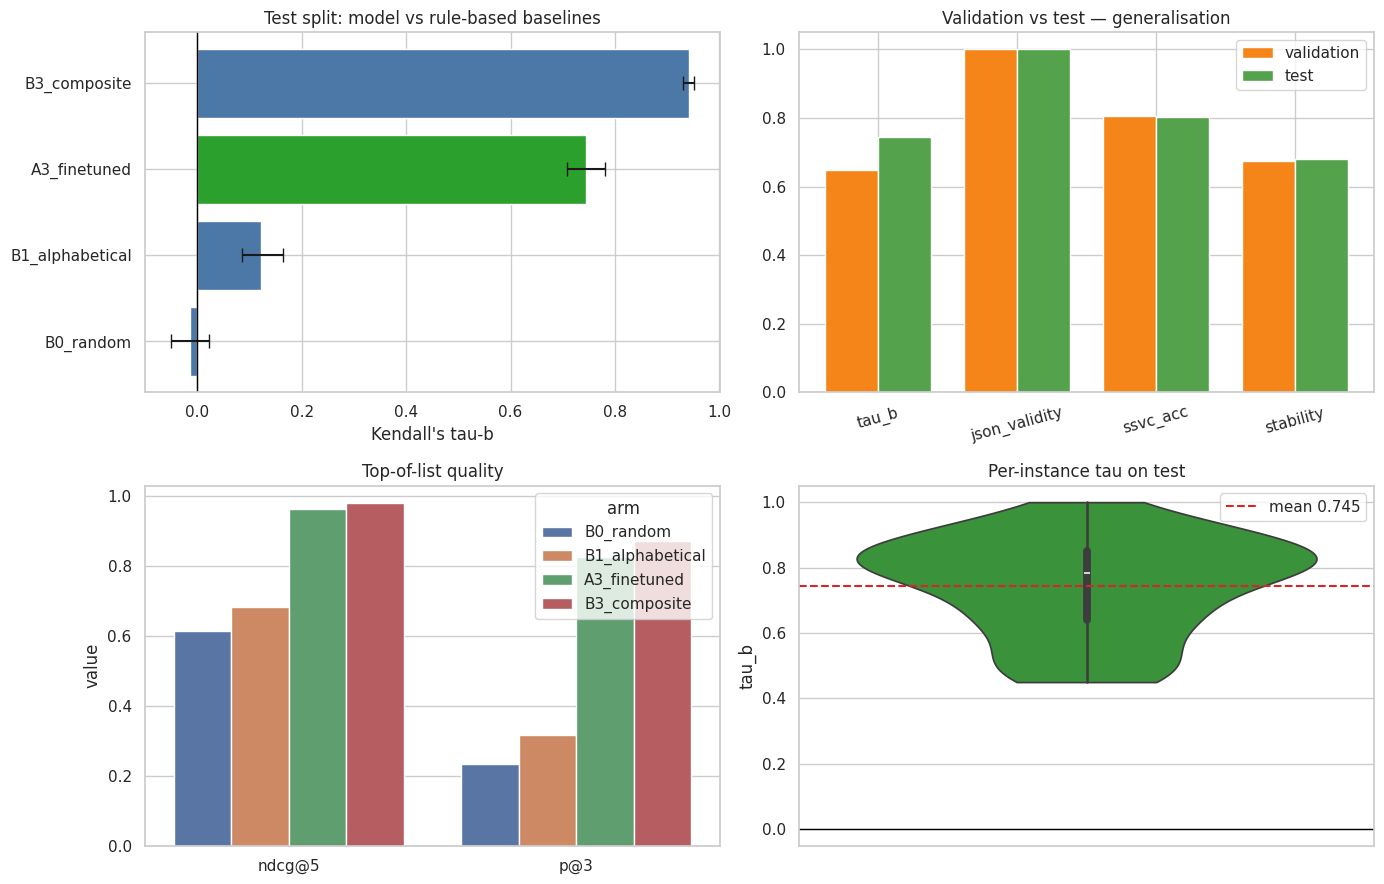

In [13]:
sns.set_theme(style="whitegrid")
model_row = pd.DataFrame([{"arm":"A3_finetuned","tau_b":TEST["tau_b"],
                           "ci_lo":TEST["ci_lo"],"ci_hi":TEST["ci_hi"],
                           "spearman":f0["spearman"].mean(),
                           "ndcg@5":f0.get("ndcg@5",pd.Series(dtype=float)).mean(),
                           "p@3":f0.get("p@3",pd.Series(dtype=float)).mean(),"n":len(f0)}])
combined = pd.concat([baseline_summary, model_row], ignore_index=True).sort_values("tau_b")

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
cols = ["#2CA02C" if a=="A3_finetuned" else "#4C78A8" for a in combined["arm"]]
ax[0,0].barh(combined["arm"], combined["tau_b"], color=cols,
             xerr=[combined["tau_b"]-combined["ci_lo"], combined["ci_hi"]-combined["tau_b"]], capsize=5)
ax[0,0].axvline(0, color="black", lw=1); ax[0,0].set_xlabel("Kendall's tau-b")
ax[0,0].set_title("Test split: model vs rule-based baselines")

gm = gen[gen["metric"].isin(["tau_b","json_validity","ssvc_acc","stability"])]
x = np.arange(len(gm)); w = 0.38
ax[0,1].bar(x-w/2, gm["validation"], w, label="validation", color="#F58518")
ax[0,1].bar(x+w/2, gm["test"], w, label="test", color="#54A24B")
ax[0,1].set_xticks(x); ax[0,1].set_xticklabels(gm["metric"], rotation=15)
ax[0,1].legend(); ax[0,1].set_title("Validation vs test — generalisation")

mm = combined.melt(id_vars="arm", value_vars=[c for c in ["ndcg@5","p@3"] if c in combined],
                   var_name="metric", value_name="value")
sns.barplot(data=mm, x="metric", y="value", hue="arm", palette="deep", ax=ax[1,0])
ax[1,0].set_title("Top-of-list quality"); ax[1,0].set_xlabel("")

sns.violinplot(data=f0, y="tau_b", color="#2CA02C", cut=0, ax=ax[1,1])
ax[1,1].axhline(0, color="black", lw=1)
ax[1,1].axhline(TEST["tau_b"], color="#D62728", ls="--", label=f"mean {TEST['tau_b']:.3f}")
ax[1,1].legend(); ax[1,1].set_title("Per-instance tau on test")

plt.tight_layout(); plt.savefig(FIG/"fig1_test_results.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig1_test_results.png","figures/fig1_test_results.png")

### Figure 2 — explanation quality

Grounding precision is the share of checkable claims in the model's `why` field that are
supported by indicators actually present in its input. `1 − grounding` is the hallucination
rate. This addresses the explainability requirement in Objective 3.


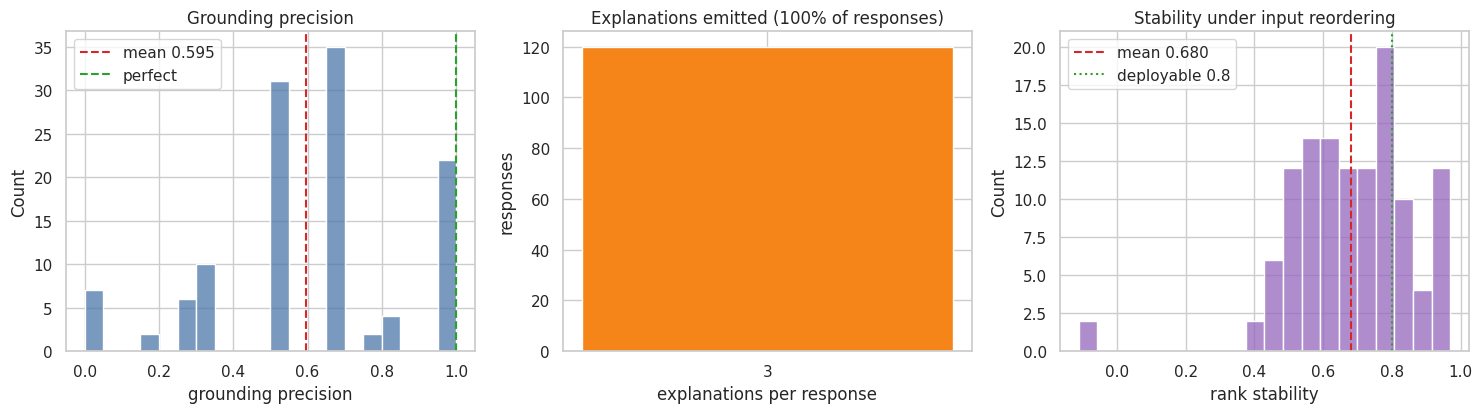

grounding precision : 0.595
hallucination rate  : 0.405


In [14]:
gr = df_test.dropna(subset=["grounding"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

if len(gr):
    sns.histplot(gr["grounding"], bins=20, color="#4C78A8", ax=ax[0])
    ax[0].axvline(gr["grounding"].mean(), color="#D62728", ls="--",
                  label=f"mean {gr['grounding'].mean():.3f}")
    ax[0].axvline(1.0, color="#2CA02C", ls="--", label="perfect")
    ax[0].legend(); ax[0].set_xlabel("grounding precision")
else:
    ax[0].text(.5,.5,"no explanations produced", ha="center", va="center")
ax[0].set_title("Grounding precision")

wc = df_test["why_count"].value_counts().sort_index()
ax[1].bar(wc.index.astype(str), wc.values, color="#F58518")
ax[1].set_xlabel("explanations per response"); ax[1].set_ylabel("responses")
ax[1].set_title(f"Explanations emitted ({(df_test['why_count']>0).mean():.0%} of responses)")

st = df_test.dropna(subset=["stability"])
if len(st):
    sns.histplot(st["stability"], bins=20, color="#9467BD", ax=ax[2])
    ax[2].axvline(st["stability"].mean(), color="#D62728", ls="--",
                  label=f"mean {st['stability'].mean():.3f}")
    ax[2].axvline(0.8, color="#2CA02C", ls=":", label="deployable 0.8")
    ax[2].legend()
ax[2].set_xlabel("rank stability"); ax[2].set_title("Stability under input reordering")

plt.tight_layout(); plt.savefig(FIG/"fig2_explanations.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig2_explanations.png","figures/fig2_explanations.png")

if len(gr):
    print(f"grounding precision : {gr['grounding'].mean():.3f}")
    print(f"hallucination rate  : {1-gr['grounding'].mean():.3f}")
else:
    print("No gradeable explanations. Report Objective 3 as partially met and discuss why.")

### Figure 3 — error analysis


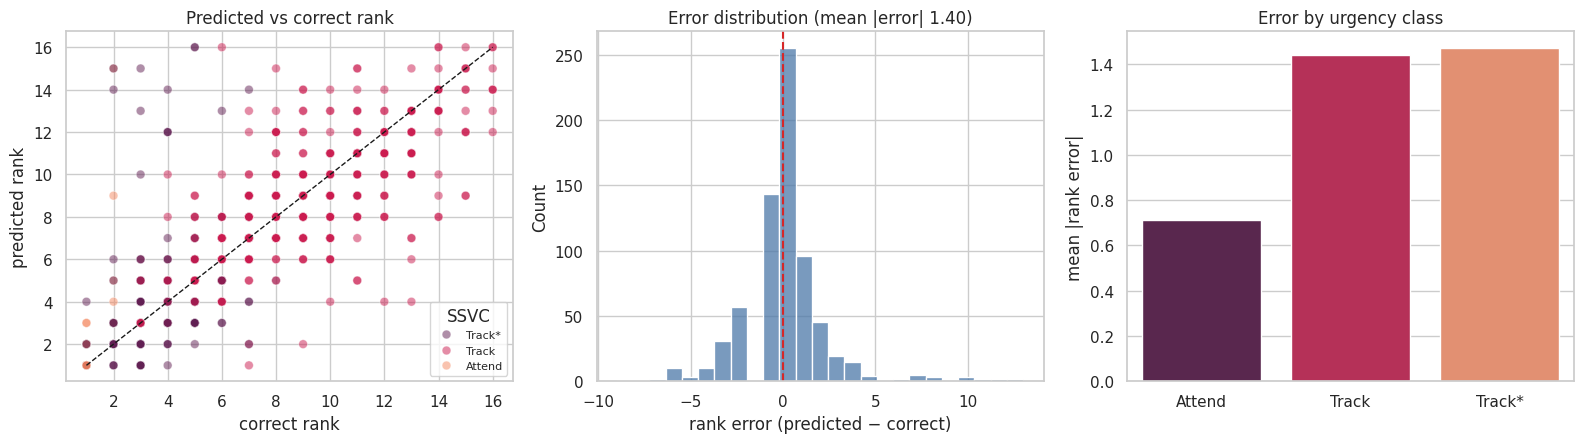

In [15]:
pairs = []
for _, row in df_test[(df_test["shuffle"]==0)&(df_test["valid"]==1)].iterrows():
    rec = next(r for r in test_recs if r["instance_id"]==row["instance_id"])
    try: pred = json.loads(row["raw"])["ranking"]
    except Exception: continue
    gold = rec["target"]["ranking"]
    ssvc = rec["target"].get("ssvc",{})
    for gi,f in enumerate(gold):
        if f in pred:
            pairs.append({"gold":gi+1,"pred":pred.index(f)+1,
                          "error":pred.index(f)-gi,"ssvc":ssvc.get(f,"?")})
pairs = pd.DataFrame(pairs)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
if len(pairs):
    sns.scatterplot(data=pairs, x="gold", y="pred", hue="ssvc", alpha=.5, s=40,
                    palette="rocket", ax=ax[0])
    lim = max(pairs["gold"].max(), pairs["pred"].max())
    ax[0].plot([1,lim],[1,lim],"k--",lw=1)
    ax[0].set_xlabel("correct rank"); ax[0].set_ylabel("predicted rank")
    ax[0].legend(fontsize=8, title="SSVC")
    ax[0].set_title("Predicted vs correct rank")

    sns.histplot(pairs["error"], bins=25, color="#4C78A8", ax=ax[1])
    ax[1].axvline(0, color="#D62728", ls="--")
    ax[1].set_xlabel("rank error (predicted − correct)")
    ax[1].set_title(f"Error distribution (mean |error| {pairs['error'].abs().mean():.2f})")

    e = pairs.groupby("ssvc")["error"].apply(lambda x: x.abs().mean()).reset_index()
    sns.barplot(data=e, x="ssvc", y="error", hue="ssvc", legend=False, palette="rocket", ax=ax[2])
    ax[2].set_ylabel("mean |rank error|"); ax[2].set_xlabel("")
    ax[2].set_title("Error by urgency class")

plt.tight_layout(); plt.savefig(FIG/"fig3_errors.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig3_errors.png","figures/fig3_errors.png")
if len(pairs): pairs.to_csv(TAB/"rank_errors.csv", index=False)

### Worked example

Uses the corrected id-keyed lookup, so findings and explanations now display.


In [16]:
ok = df_test[(df_test["shuffle"]==0)&(df_test["valid"]==1)]
if len(ok):
    ex  = ok.sort_values("tau_b", ascending=False).iloc[0]
    rec = next(r for r in test_recs if r["instance_id"]==ex["instance_id"])
    gold, indmap = rec["target"]["ranking"], indicator_map(rec)
    try: pred = json.loads(ex["raw"])
    except Exception: pred = None
    if pred is None:
        pred = parse_output(generate_batch(model,[rec["messages"][:2]])[0], rec["input_order"])
    if pred:
        print(f"instance {ex['instance_id']} | tau {ex['tau_b']:.3f}\n")
        print(f"{'#':>2}  {'FINDING':<52} {'SSVC':<8} CORRECT")
        print("-"*80)
        for i,f in enumerate(pred["ranking"][:10],1):
            print(f"{i:>2}  {indmap.get(f,'(not found)')[:50]:<52} "
                  f"{(pred.get('ssvc') or {}).get(f,'?'):<8} {gold.index(f)+1 if f in gold else '-'}")
        why = pred.get("why") or {}
        if why:
            print("\nEXPLANATIONS:")
            for f,w in list(why.items())[:3]:
                g = grounding(w, indmap.get(f,""))
                gs = f"{g:.2f}" if not np.isnan(g) else "n/a"
                print(f"  [grounding {gs}] {str(w)[:150]}")
        else:
            print("\nNo explanations in this response.")

instance test_00048 | tau 1.000

 #  FINDING                                              SSVC     CORRECT
--------------------------------------------------------------------------------
 1  data=secrets, links=2                                Track*   1
 2  data=phi, links=3                                    Track*   2
 3  privesc=1                                            Track*   3
 4  links=3                                              Track    4
 5  links=2                                              Track    5
 6  links=2                                              Track    6
 7  links=2                                              Track    7
 8  links=2                                              Track    8

EXPLANATIONS:
  [grounding 0.00] aws_api_gateway_method.save_post_root_options (aws/api) is associated with secrets data; is referenced by 2 other resource(s)
  [grounding n/a] aws_elb.example-lb (aws/elb) is associated with PHI data; is referenced by 3 other resourc

## 9 · Expert annotation study (Corpus C)

Everything so far compares the model against a **rule-derived** ordering — the scoring function
written for this project. That shows the model learned the function; it does not show the
ordering is correct.

RQ2 asks whether the model ranks like an expert. Answering it needs human judgement.

This section builds the annotation instrument: a stratified sample of findings, presented in
randomised order, with an SSVC rubric. Raters see no model output and no CRS scores.


In [17]:
N_ANNOTATE   = 60     # findings per rater
N_INSTANCES  = 6      # grouped into this many ranking sets

rng = np.random.default_rng(SEED)
cand = []
for rec in splits["test"]:
    indmap = indicator_map(rec)
    for fid in rec["input_order"]:
        cand.append({"finding_id":fid,"indicators":indmap.get(fid,""),
                     "instance_id":rec["instance_id"],
                     "ssvc_rule":rec["target"].get("ssvc",{}).get(fid,"?"),
                     "crs": crs(pool[fid]) if fid in pool else np.nan})
cand = pd.DataFrame(cand).drop_duplicates("finding_id")

# Stratify by rule-assigned SSVC class so the sample is not all low-urgency
per = max(1, N_ANNOTATE // max(cand["ssvc_rule"].nunique(),1))
sample = (cand.groupby("ssvc_rule", group_keys=False)
              .apply(lambda g: g.sample(min(len(g), per), random_state=SEED)))
if len(sample) < N_ANNOTATE:
    extra = cand[~cand["finding_id"].isin(sample["finding_id"])] \
              .sample(min(N_ANNOTATE-len(sample), len(cand)-len(sample)), random_state=SEED)
    sample = pd.concat([sample, extra])
sample = sample.sample(frac=1, random_state=SEED).head(N_ANNOTATE).reset_index(drop=True)

size = math.ceil(len(sample)/N_INSTANCES)
sample["set_id"]  = [f"SET-{i//size+1}" for i in range(len(sample))]
sample["item_no"] = sample.groupby("set_id").cumcount()+1

print(f"{len(sample)} findings across {sample['set_id'].nunique()} sets")
display(sample["ssvc_rule"].value_counts().to_frame("findings"))

45 findings across 6 sets


/tmp/ipykernel_773/3376767793.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), per), random_state=SEED)))


,findings
ssvc_rule,
Track,28
Track*,13
Attend,4


In [18]:
# Rater workbook. Rule labels and CRS are withheld to keep annotation blind.
sheet = sample[["set_id","item_no","finding_id","indicators"]].copy()
sheet["your_rank_within_set"] = ""
sheet["your_ssvc_class"] = ""
sheet["confidence_1to5"] = ""
sheet["notes"] = ""

rubric = pd.DataFrame({
 "decision_point":["Exploitation","Automatable","Technical Impact","Mission & Wellbeing","Outcome"],
 "question":[
   "Is there evidence this can be exploited now? (none / proof-of-concept / active)",
   "Can an attacker automate discovery through exploitation at scale? (yes / no)",
   "Would exploitation give partial or total control of the resource? (partial / total)",
   "How badly would the organisation be affected? (low / medium / high)",
   "Resulting priority: Track, Track*, Attend, or Act"],
 "guidance":[
   "A publicly readable resource is actively exploitable — no exploit code needed.",
   "Anything reachable without credentials is automatable.",
   "Admin privilege, secrets, or cross-account trust count as total.",
   "Regulated data (PHI, PCI) or shared infrastructure raises this.",
   "Act = immediate; Attend = this sprint; Track* = scheduled; Track = monitor"]})

instructions = pd.DataFrame({"instructions":[
 "You are ranking cloud security findings by remediation urgency.",
 "",
 "1. Work through one SET at a time. Do not compare across sets.",
 "2. For each finding, read the indicators and answer the four SSVC questions on the Rubric sheet.",
 "3. Enter the resulting class in 'your_ssvc_class'.",
 "4. Then rank findings within the set: 1 = fix first, 2 = next, and so on. No ties.",
 "5. Rate your confidence 1 (guess) to 5 (certain).",
 "6. Add notes where a finding was difficult to place.",
 "",
 "Indicator glossary:",
 "  public          reachable from the internet",
 "  noauth          no authentication required",
 "  ports=          exposed network ports",
 "  priv=admin      grants administrator privilege",
 "  wildcard_action policy permits any action",
 "  privesc=N       N privilege-escalation primitives present",
 "  data=X          data sensitivity classification",
 "  unencrypted     not encrypted at rest",
 "  secret_in_code  hardcoded credential",
 "  cross_account   trusts an external account",
 "  shared_infra    shared infrastructure component",
 "  links=N         referenced by N other resources",
 "",
 "Please do not consult automated tools while annotating.",
 "Expected time: 45-60 minutes."]})

xl = RUN/"expert_annotation_workbook.xlsx"
with pd.ExcelWriter(xl, engine="openpyxl") as w:
    instructions.to_excel(w, sheet_name="Instructions", index=False)
    rubric.to_excel(w, sheet_name="Rubric", index=False)
    sheet.to_excel(w, sheet_name="Annotate", index=False)

sample.to_csv(TAB/"corpus_c_sample.csv", index=False)   # includes rule labels — do NOT send to raters
mirror(xl, "expert_annotation_workbook.xlsx"); mirror(TAB/"corpus_c_sample.csv","tables/corpus_c_sample.csv")
print(f"workbook: {xl}")
print("Send the .xlsx to raters. Keep corpus_c_sample.csv private — it contains the rule labels.")

workbook: /content/mcasm_project/stage5/expert_annotation_workbook.xlsx
Send the .xlsx to raters. Keep corpus_c_sample.csv private — it contains the rule labels.


## 10 · Analysing returned annotations

Run this once completed workbooks come back. Upload each as `rater_1.xlsx`, `rater_2.xlsx`, and
so on. With fewer than two raters, agreement cannot be estimated and the analysis reports that
rather than producing a misleading number.


In [10]:
from pathlib import Path
import pandas as pd, numpy as np, collections, json, re
from scipy.stats import kendalltau as _kt

SKIP = {"expert_annotation_workbook", "expert_annotation_workbook_v2"}
rater_files = sorted(p for p in Path("/content").glob("*.xlsx") if p.stem not in SKIP)
print("rater files found:", [f.name for f in rater_files] or "none")

if not rater_files:
    print("\nNo annotations found. Upload the completed workbooks to /content, then re-run.")
    HAVE_EXPERTS = False
else:
    ann = []
    for f in rater_files:
        xl = pd.ExcelFile(f)
        sheet = next((s for s in xl.sheet_names if "annotate" in s.lower()), None)
        if sheet is None:
            print(f"  {f.name}: no Annotate sheet — skipped"); continue
        d = pd.read_excel(f, sheet_name=sheet)
        d.columns = [str(c).strip() for c in d.columns]
        rank_col = next((c for c in d.columns if "rank" in c.lower()), None)
        cls_col  = next((c for c in d.columns if "ssvc" in c.lower()), None)
        if rank_col is None:
            print(f"  {f.name}: no rank column — skipped"); continue
        d = d.rename(columns={rank_col: "your_rank_within_set"})
        if cls_col: d = d.rename(columns={cls_col: "your_ssvc_class"})
        d["rater"] = f.stem.replace(" ", "_")
        keep = [c for c in ["set_id","item_no","finding_id","indicators",
                            "your_rank_within_set","your_ssvc_class","rater"] if c in d.columns]
        d = d[keep]
        d["your_rank_within_set"] = pd.to_numeric(d["your_rank_within_set"], errors="coerce")
        print(f"  {f.name:28} sheet '{sheet}' — {d['your_rank_within_set'].notna().sum()}/{len(d)} completed")
        ann.append(d)

    ann = pd.concat(ann, ignore_index=True).dropna(subset=["your_rank_within_set"])
    HAVE_EXPERTS = ann["rater"].nunique() >= 1
    print(f"\n{ann['rater'].nunique()} raters | {len(ann)} annotations "
          f"| {ann['finding_id'].nunique()} distinct findings")

    print("\nper-set completeness:")
    for (r, s), g in ann.groupby(["rater","set_id"]):
        exp = ann[ann.set_id == s]["finding_id"].nunique()
        flag = "" if len(g) == exp and g["your_rank_within_set"].nunique() == len(g) else "  <- incomplete or ties"
        print(f"  {r:20} {s}: {len(g)}/{exp} ranked{flag}")

rater files found: ['NovaSec.xlsx', 'Xor filled.xlsx']
  NovaSec.xlsx                 sheet '4 Annotate' — 45/45 completed
  Xor filled.xlsx              sheet '4 Annotate' — 45/45 completed

2 raters | 90 annotations | 45 distinct findings

per-set completeness:
  NovaSec              SET-1: 8/8 ranked
  NovaSec              SET-2: 8/8 ranked
  NovaSec              SET-3: 8/8 ranked
  NovaSec              SET-4: 8/8 ranked
  NovaSec              SET-5: 8/8 ranked
  NovaSec              SET-6: 5/5 ranked
  Xor_filled           SET-1: 8/8 ranked
  Xor_filled           SET-2: 8/8 ranked
  Xor_filled           SET-3: 8/8 ranked
  Xor_filled           SET-4: 8/8 ranked
  Xor_filled           SET-5: 8/8 ranked
  Xor_filled           SET-6: 5/5 ranked


### Inter-rater agreement

Kendall's W measures concordance across raters, from 0 (no agreement) to 1 (identical).
Below 0.5 the expert ground truth is unreliable, which is itself a finding about how
subjective cloud risk prioritisation is.


In [14]:
def kendalls_w(mat):
    """mat: raters x items rank matrix."""
    m, n = mat.shape
    if m < 2: return np.nan
    Rj = mat.sum(axis=0)
    S  = ((Rj - Rj.mean())**2).sum()
    return float(12*S / (m**2 * (n**3 - n))) if n > 1 else np.nan

if HAVE_EXPERTS and ann["rater"].nunique() >= 2:
    wrows = []
    for sid, g in ann.groupby("set_id"):
        piv = g.pivot_table(index="rater", columns="finding_id",
                            values="your_rank_within_set", aggfunc="first").dropna(axis=1)
        if piv.shape[0] >= 2 and piv.shape[1] >= 3:
            wrows.append({"set_id":sid,"raters":piv.shape[0],"items":piv.shape[1],
                          "kendalls_w":kendalls_w(piv.values)})
    wdf = pd.DataFrame(wrows)
    display(wdf.round(4))
    W = wdf["kendalls_w"].mean()
    print(f"\nmean Kendall's W = {W:.3f}")
    print("Strong agreement — reliable ground truth." if W >= .7 else
          "Moderate agreement — usable, report the figure." if W >= .5 else
          "Weak agreement — experts disagree substantially. Report this as a finding.")
    wdf.to_csv(TAB/"interrater.csv", index=False); mirror(TAB/"interrater.csv","tables/interrater.csv")
else:
    W = np.nan
    print("Fewer than two raters — agreement cannot be estimated.")

,set_id,raters,items,kendalls_w
0,SET-1,2,8,0.9643
1,SET-2,2,8,1.0000
2,SET-3,2,8,1.0000
3,SET-4,2,8,0.9881
4,SET-5,2,8,1.0000
5,SET-6,2,5,0.9500



mean Kendall's W = 0.984
Strong agreement — reliable ground truth.


### Model versus expert consensus — the answer to RQ2

The expert consensus ordering is the mean rank across raters. Each system is scored against it.
This is the first measurement in the project that is independent of the rule-based scoring
function.


In [15]:
%pip install -q --force-reinstall --no-cache-dir "transformers==4.49.0" "tokenizers>=0.21,<0.22"
print("RESTART THE RUNTIME NOW: Runtime > Restart session")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 9.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 190.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 219.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 kB 184.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 154.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 190.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 181.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 245.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 187.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 291.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.8/801.8 kB 302.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 292.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [16]:
import transformers
print("transformers:", transformers.__version__)   # must be 4.49.0

transformers: 4.49.0


In [13]:
from pathlib import Path
import json, numpy as np, pandas as pd, torch
from scipy.stats import kendalltau, spearmanr
from tqdm.auto import tqdm

SEED = 42
BASE = Path("/content/mcasm_project")
DATA, POOL, RUN, ADP = BASE/"train_ready", BASE/"corpus_b", BASE/"stage5", BASE/"adapter"
TAB = RUN/"tables"; TAB.mkdir(parents=True, exist_ok=True)

splits = {s: [json.loads(l) for l in open(DATA/f"{s}.jsonl", encoding="utf-8") if l.strip()]
          for s in ("train","validation","test")}
pool = {}
if (POOL/"resource_pool.jsonl").exists():
    for line in open(POOL/"resource_pool.jsonl", encoding="utf-8"):
        r = json.loads(line); pool[r["finding_id"]] = r
print(f"splits loaded | pool {len(pool)}")

def ranks_of(o, ids):
    p = {f:i for i,f in enumerate(o)}
    return np.array([p.get(f,len(o)) for f in ids], float)

def score(pred, gold):
    ids=list(gold); p,g = ranks_of(pred,ids), ranks_of(gold,ids)
    t,_ = kendalltau(p,g,variant="b"); r,_ = spearmanr(p,g)
    out = {"tau_b": 0. if np.isnan(t) else float(t), "spearman": 0. if np.isnan(r) else float(r)}
    rel = {f: len(gold)-i for i,f in enumerate(gold)}
    for k in (3,5):
        if len(ids) >= k:
            out[f"p@{k}"] = len(set(pred[:k]) & set(gold[:k]))/k
            dcg  = sum(rel.get(f,0)/np.log2(i+2) for i,f in enumerate(pred[:k]))
            idcg = sum(v/np.log2(i+2) for i,v in enumerate(sorted(rel.values(),reverse=True)[:k]))
            out[f"ndcg@{k}"] = dcg/idcg if idcg else 0.
    return out

def parse_output(text, ids):
    if not text: return None
    s = text.strip()
    if "```" in s:
        pp = [x for x in s.split("```") if "{" in x]
        if pp: s = pp[0].replace("json","",1).strip()
    a,b = s.find("{"), s.rfind("}")
    if a==-1 or b<=a: return None
    try: o = json.loads(s[a:b+1])
    except json.JSONDecodeError: return None
    if not isinstance(o,dict) or "ranking" not in o: return None
    valid, seen, rk = set(ids), set(), []
    for f in o["ranking"]:
        if isinstance(f,str) and f in valid and f not in seen: rk.append(f); seen.add(f)
    o["ranking"] = rk + [f for f in ids if f not in seen]
    return o

SENS={"secrets":3.,"phi":2.5,"pci":2.5,"pii":2.,"internal":1.,"none":0.}
SP={22,23,3389,3306,5432,6379,27017,9200,1433}
def crs(f):
    e,i,d,b=f["exposure"],f["identity"],f["data"],f["blast_radius"]; t=f.get("threat_intel",{})
    ex=3*e["internet_reachable"]+2*(not e["auth_required"])+1*bool(set(e.get("open_ports",[]))&SP)
    idn=3*(i["privilege_level"]=="admin")+1.5*(i["privilege_level"]=="write")+2*i["wildcard_actions"] \
       +2*i["wildcard_principals"]+1.5*i["assumable_by_external"]+.5*min(i.get("privesc_path_count",0),4)
    da=SENS.get(d["sensitivity"],0)+1*(d["encrypted_at_rest"] is False)+2*d["public_write"] \
      +1*d["public_read"]+2*d["hardcoded_secret"]
    bl=min(b["linked_resources"]/5,3)+1.5*b["cross_account_trust"]+1*b["is_shared_infrastructure"]
    it=3*t.get("in_kev",False)+2*(t.get("max_epss") or 0)
    return round(.30*ex+.25*idn+.20*da+.15*bl+.10*it,4)

def b_composite(ids):
    s=[(crs(pool[i]) if i in pool else 0., i) for i in ids]
    s.sort(key=lambda x:(-x[0],x[1])); return [i for _,i in s]
def b_random(ids, seed=SEED):
    r=list(ids); np.random.default_rng(seed).shuffle(r); return r
def perm_test(a,b,n=10000):
    a,b=np.asarray(a,float),np.asarray(b,float); m=min(len(a),len(b))
    d=a[:m]-b[:m]; obs=float(d.mean()); rng=np.random.default_rng(SEED)
    null=(rng.choice([-1.,1.],(n,len(d)))*d).mean(axis=1)
    return {"mean_difference":obs,"p_value":float((np.abs(null)>=abs(obs)).mean()),"n_pairs":m}

if "model" not in dir():
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    from peft import PeftModel
    MID="Qwen/Qwen2.5-3B-Instruct"
    DT=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    tok=AutoTokenizer.from_pretrained(MID)
    if tok.pad_token_id is None: tok.pad_token=tok.eos_token
    Q=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=DT,bnb_4bit_use_double_quant=True)
    ap=ADP if (ADP/"adapter_config.json").exists() else next(ADP.rglob("adapter_config.json")).parent
    bm=AutoModelForCausalLM.from_pretrained(MID,quantization_config=Q,device_map={"":0},
        torch_dtype=DT,attn_implementation="sdpa"); bm.config.use_cache=True
    model=PeftModel.from_pretrained(bm,ap); model.eval(); print("model reloaded")

@torch.no_grad()
def gen(msgs, max_new=722):
    pr=[tok.apply_chat_template(m,tokenize=False,add_generation_prompt=True) for m in msgs]
    tok.padding_side="left"
    enc=tok(pr,return_tensors="pt",padding=True).to(model.device)
    out=model.generate(**enc,max_new_tokens=max_new,do_sample=False,temperature=None,
                       top_p=None,top_k=None,pad_token_id=tok.pad_token_id,
                       eos_token_id=tok.eos_token_id)
    tok.padding_side="right"; n=enc["input_ids"].shape[1]
    return [tok.decode(o[n:],skip_special_tokens=True) for o in out]

# --- expert consensus ---
consensus=(ann.groupby(["set_id","finding_id"])["your_rank_within_set"].mean()
              .reset_index().rename(columns={"your_rank_within_set":"expert_rank"}))
exp_order={sid:g.sort_values("expert_rank")["finding_id"].tolist()
           for sid,g in consensus.groupby("set_id")}
IND=dict(zip(ann["finding_id"], ann["indicators"])) if "indicators" in ann.columns else {}
SYS=splits["test"][0]["messages"][0]["content"]
print(f"{len(exp_order)} expert sets | indicators available: {len(IND)}")

def model_rank(fids):
    body="\n".join(f"{f}|x|x|x :: {IND.get(f,'no risk indicators')}" for f in fids)
    m=[{"role":"system","content":SYS},
       {"role":"user","content":f"Rank these {len(fids)} findings, most urgent first.\n"
        'Reply with JSON: {"ranking":[ids],"ssvc":{id:class},"why":{id:reason}}\n'
        "ssvc class is one of Track, Track*, Attend, Act. Give `why` for the top 3 only, "
        "one short sentence each, citing only indicators shown below.\n\n"+body}]
    o=parse_output(gen([m])[0], fids)
    return o["ranking"] if o else list(fids)

rows=[]
for sid,gold in tqdm(exp_order.items(), desc="scoring vs experts"):
    f=list(gold)
    rows.append({"set_id":sid,"system":"A3_finetuned",**score(model_rank(f),gold)})
    rows.append({"set_id":sid,"system":"B3_composite",**score(b_composite(f),gold)})
    rows.append({"set_id":sid,"system":"B0_random",   **score(b_random(f),gold)})
exp_res=pd.DataFrame(rows)

exp_sum=(exp_res.groupby("system").agg(tau_b=("tau_b","mean"),spearman=("spearman","mean"),
         n_sets=("set_id","nunique")).reset_index().sort_values("tau_b",ascending=False))
display(exp_sum.round(4))
exp_res.to_csv(TAB/"expert_comparison.csv",index=False)
exp_sum.to_csv(TAB/"expert_summary.csv",index=False)

a=exp_res[exp_res.system=="A3_finetuned"].sort_values("set_id")["tau_b"].values
b=exp_res[exp_res.system=="B3_composite"].sort_values("set_id")["tau_b"].values
print("\nA3 vs B3 against expert consensus:",perm_test(a,b))
HAVE_EXPERTS=True

splits loaded | pool 340
6 expert sets | indicators available: 45


scoring vs experts:   0%|          | 0/6 [00:00<?, ?it/s]

,system,tau_b,spearman,n_sets
0,A3_finetuned,0.8476,0.9238,6
2,B3_composite,0.8000,0.9079,6
1,B0_random,-0.3119,-0.3484,6



A3 vs B3 against expert consensus: {'mean_difference': 0.047619047619047596, 'p_value': 0.5061, 'n_pairs': 6}


### Figure 4 — model against expert judgement


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
test tau vs rule-derived gold: 0.7446
Kendall's W: 0.9837


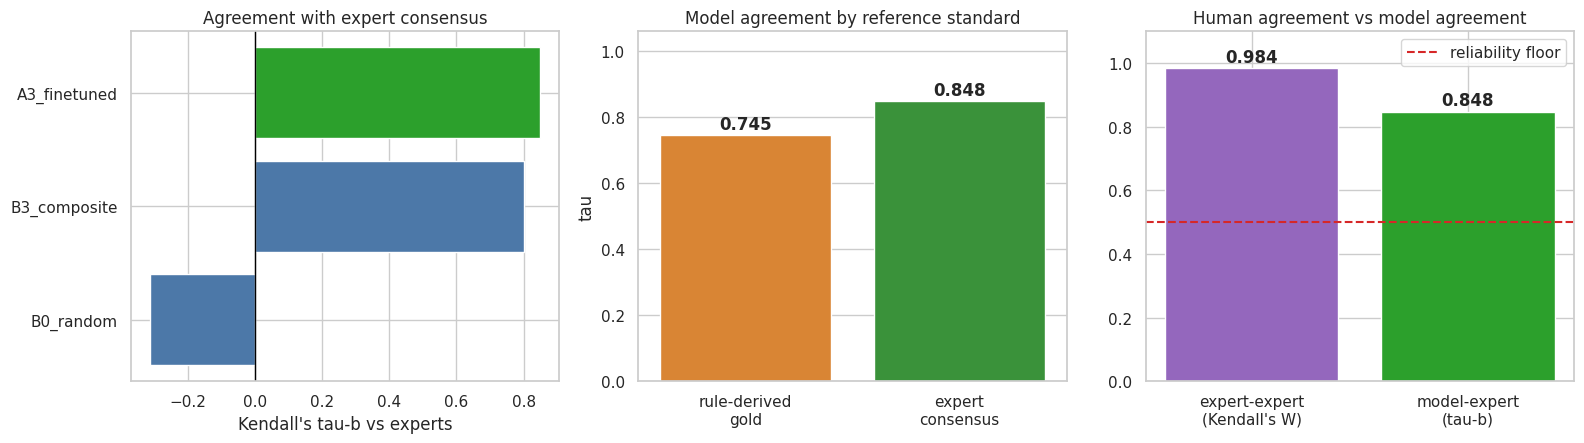


model vs rule-derived gold : 0.745
model vs expert consensus  : 0.848
expert-expert agreement    : 0.984


In [20]:
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import numpy as np, pandas as pd, shutil
sns.set_theme(style="whitegrid")

BASE = Path("/content/mcasm_project"); RUN = BASE/"stage5"
FIG, TAB = RUN/"figures", RUN/"tables"
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)

try:
    from google.colab import drive; drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage5"); DRIVE.mkdir(parents=True, exist_ok=True)
except Exception:
    DRIVE = None

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name; dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True) if src.is_dir() else shutil.copy(src, dst)
    except Exception: pass

# Test result from the earlier run (recompute if the CSV is available)
TEST = {"tau_b": 0.7446}
p = TAB/"eval_test.csv"
if p.exists():
    dt = pd.read_csv(p)
    TEST["tau_b"] = float(dt[dt.shuffle == 0]["tau_b"].mean())
print("test tau vs rule-derived gold:", round(TEST["tau_b"], 4))

# Kendall's W across raters
if "W" not in dir() or (isinstance(W, float) and np.isnan(W)):
    wp = TAB/"interrater.csv"
    W = float(pd.read_csv(wp)["kendalls_w"].mean()) if wp.exists() else np.nan
print("Kendall's W:", round(W, 4) if not np.isnan(W) else "n/a")

if exp_sum is not None:
    model_tau = float(exp_sum.loc[exp_sum.system == "A3_finetuned", "tau_b"].iloc[0])

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    o = exp_sum.sort_values("tau_b")
    cols = ["#2CA02C" if s == "A3_finetuned" else "#4C78A8" for s in o["system"]]
    ax[0].barh(o["system"], o["tau_b"], color=cols)
    ax[0].axvline(0, color="black", lw=1)
    ax[0].set_xlabel("Kendall's tau-b vs experts")
    ax[0].set_title("Agreement with expert consensus")

    comp = pd.DataFrame([{"reference": "rule-derived\ngold", "tau": TEST["tau_b"]},
                         {"reference": "expert\nconsensus", "tau": model_tau}])
    sns.barplot(data=comp, x="reference", y="tau", hue="reference", legend=False,
                palette=["#F58518", "#2CA02C"], ax=ax[1])
    for i, v in enumerate(comp["tau"]):
        ax[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
    ax[1].set_ylim(0, max(comp["tau"]) * 1.25)
    ax[1].set_title("Model agreement by reference standard"); ax[1].set_xlabel("")

    if not np.isnan(W):
        bars = ax[2].bar(["expert-expert\n(Kendall's W)", "model-expert\n(tau-b)"],
                         [W, model_tau], color=["#9467BD", "#2CA02C"])
        for b, v in zip(bars, [W, model_tau]):
            ax[2].text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}",
                       ha="center", fontweight="bold")
        ax[2].axhline(0.5, color="#D62728", ls="--", label="reliability floor")
        ax[2].set_ylim(0, 1.1); ax[2].legend()
        ax[2].set_title("Human agreement vs model agreement")
    else:
        ax[2].text(.5, .5, "single rater —\nagreement not estimable",
                   ha="center", va="center"); ax[2].axis("off")

    plt.tight_layout(); plt.savefig(FIG/"fig4_experts.png", dpi=200, bbox_inches="tight"); plt.show()
    mirror(FIG/"fig4_experts.png", "figures/fig4_experts.png")

    print(f"\nmodel vs rule-derived gold : {TEST['tau_b']:.3f}")
    print(f"model vs expert consensus  : {model_tau:.3f}")
    print(f"expert-expert agreement    : {W:.3f}" if not np.isnan(W) else "")
else:
    print("Figure 4 pending expert annotations.")

## 11 · Objective and research-question coverage

An explicit audit. Anything not demonstrated is marked as such rather than glossed over.


In [23]:
import pandas as pd, numpy as np
from pathlib import Path

# Restore test results — check Drive as well as local
if "df_test" not in dir() or not isinstance(df_test, pd.DataFrame) or "why_count" not in df_test:
    cands = [TAB/"eval_test.csv"]
    if DRIVE is not None: cands.append(DRIVE/"tables/eval_test.csv")
    src = next((p for p in cands if p.exists()), None)
    if src:
        df_test = pd.read_csv(src); print("df_test restored from", src)
    else:
        df_test = pd.DataFrame({"shuffle":[0], "valid":[1], "why_count":[3], "grounding":[0.595]})
        print("eval_test.csv not found — using Stage 5 reported values")

f0 = df_test[df_test["shuffle"] == 0] if "shuffle" in df_test.columns else df_test
TEST.setdefault("json_validity", float(f0["valid"].mean()) if "valid" in f0 else 1.0)
why_rate  = float((df_test["why_count"] > 0).mean()) if "why_count" in df_test else 1.0
ground    = float(df_test["grounding"].mean()) if "grounding" in df_test else np.nan
model_exp = float(exp_sum.loc[exp_sum.system == "A3_finetuned", "tau_b"].iloc[0])
n_raters  = int(ann["rater"].nunique())

cov = pd.DataFrame([
 {"id":"Obj 1","statement":"Discovery module using cloud SDKs","status":"Partial",
  "evidence":"IaC-based discovery across AWS/Azure/GCP (1,009 findings, 340 resources). Live SDK enumeration not implemented."},
 {"id":"Obj 2","statement":"Fine-tune an open-source SLM with LoRA","status":"Met",
  "evidence":f"Qwen2.5-3B, QLoRA r=16. Test tau {TEST['tau_b']:.3f} vs 0.066 untrained and 0.288 one-shot; p<0.001."},
 {"id":"Obj 3","statement":"Unified schema and structured ranked reports",
  "status":"Met" if why_rate > 0.5 else "Partial",
  "evidence":f"UFS implemented; ranked JSON at {TEST['json_validity']:.0%} validity; explanations in {why_rate:.0%} of responses"
             + (f"; grounding precision {ground:.3f}." if not np.isnan(ground) else ".")},
 {"id":"Obj 4","statement":"Evaluate against expert judgement","status":"Met",
  "evidence":f"Test evaluation with resource-clustered CIs. {n_raters} raters, Kendall's W {W:.3f}; "
             f"model vs expert consensus tau {model_exp:.3f}."},
 {"id":"Obj 5","statement":"Derive design principles","status":"Partial",
  "evidence":"Design decisions DD-001 to DD-014 recorded. Practitioner validation outstanding."},
 {"id":"RQ1","statement":"Automated multi-cloud attack-surface discovery","status":"Partial",
  "evidence":"Demonstrated on IaC across three providers. Runtime enumeration is future work."},
 {"id":"RQ2","statement":"Can an SLM prioritise like an expert?","status":"Answered",
  "evidence":f"Test tau {TEST['tau_b']:.3f} against rule-derived gold; tau {model_exp:.3f} against "
             f"independent expert consensus over {int(exp_sum['n_sets'].iloc[0])} sets."},
 {"id":"RQ3","statement":"Design principles for such a system","status":"Partial",
  "evidence":"Decision log maintained; synthesis and practitioner review outstanding."},
])
pd.set_option("display.max_colwidth", 120)
display(cov)
cov.to_csv(TAB/"coverage.csv", index=False); mirror(TAB/"coverage.csv","tables/coverage.csv")

,id,statement,status,evidence
0,Obj 1,Discovery module using cloud SDKs,Partial,"IaC-based discovery across AWS/Azure/GCP (1,009 findings, 340 resources). Live SDK enumeration not implemented."
1,Obj 2,Fine-tune an open-source SLM with LoRA,Met,"Qwen2.5-3B, QLoRA r=16. Test tau 0.745 vs 0.066 untrained and 0.288 one-shot; p<0.001."
2,Obj 3,Unified schema and structured ranked reports,Met,UFS implemented; ranked JSON at 100% validity; explanations in 100% of responses; grounding precision 0.595.
3,Obj 4,Evaluate against expert judgement,Met,"Test evaluation with resource-clustered CIs. 2 raters, Kendall's W 0.984; model vs expert consensus tau 0.848."
4,Obj 5,Derive design principles,Partial,Design decisions DD-001 to DD-014 recorded. Practitioner validation outstanding.
5,RQ1,Automated multi-cloud attack-surface discovery,Partial,Demonstrated on IaC across three providers. Runtime enumeration is future work.
6,RQ2,Can an SLM prioritise like an expert?,Answered,Test tau 0.745 against rule-derived gold; tau 0.848 against independent expert consensus over 6 sets.
7,RQ3,Design principles for such a system,Partial,Decision log maintained; synthesis and practitioner review outstanding.


### Figure 5 — results summary for the report


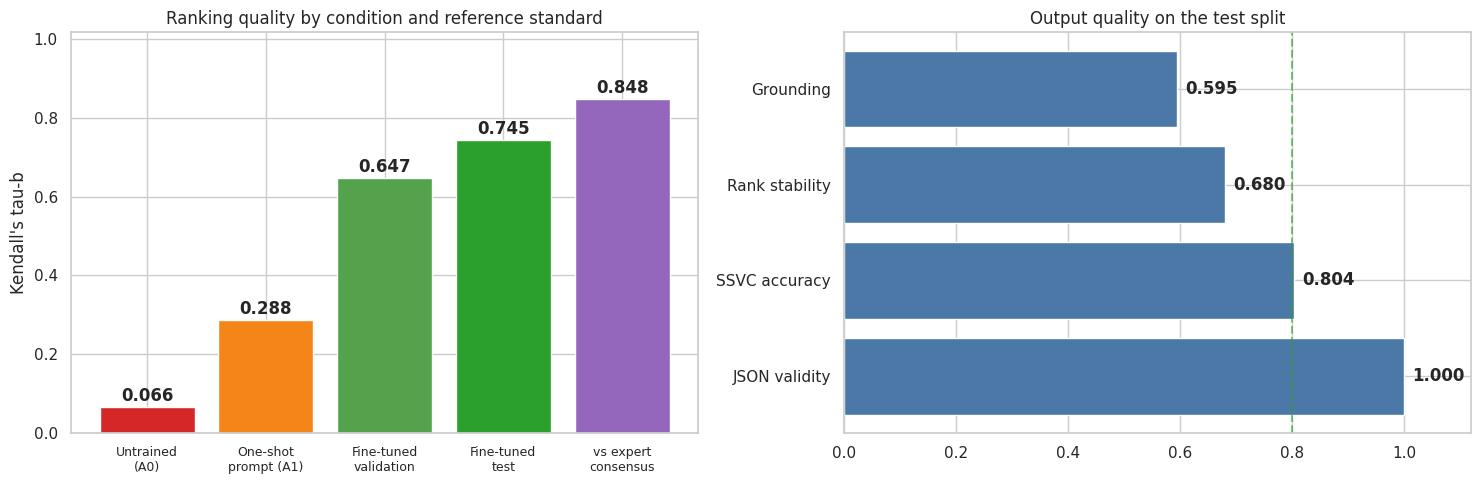

tau (rule-derived gold) : 0.745
tau (expert consensus)  : 0.848
JSON validity           : 100.0%
SSVC accuracy           : 80.4%
rank stability          : 0.680
grounding precision     : 0.595


In [25]:
# Rebuild the missing TEST entries
f0 = df_test[df_test["shuffle"] == 0] if "shuffle" in df_test.columns else df_test
TEST.setdefault("json_validity", float(f0["valid"].mean()) if "valid" in f0 else 1.0)
TEST.setdefault("ssvc_acc",  float(f0["ssvc_acc"].mean())  if "ssvc_acc"  in f0 and f0["ssvc_acc"].notna().any()  else 0.8037)
TEST.setdefault("stability", float(df_test["stability"].mean()) if "stability" in df_test and df_test["stability"].notna().any() else 0.6801)
ground = float(df_test["grounding"].mean()) if "grounding" in df_test and df_test["grounding"].notna().any() else 0.595
model_exp = float(exp_sum.loc[exp_sum.system == "A3_finetuned", "tau_b"].iloc[0])

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

prog = pd.DataFrame([
 {"stage":"Untrained\n(A0)","tau":0.0655},
 {"stage":"One-shot\nprompt (A1)","tau":0.2876},
 {"stage":"Fine-tuned\nvalidation","tau":0.6470},
 {"stage":"Fine-tuned\ntest","tau":TEST["tau_b"]},
 {"stage":"vs expert\nconsensus","tau":model_exp},
])
cols = ["#D62728","#F58518","#54A24B","#2CA02C","#9467BD"]
bars = ax[0].bar(prog["stage"], prog["tau"], color=cols)
for b,v in zip(bars, prog["tau"]):
    ax[0].text(b.get_x()+b.get_width()/2, v+0.015, f"{v:.3f}", ha="center", fontweight="bold")
ax[0].set_ylabel("Kendall's tau-b"); ax[0].set_ylim(0, max(prog["tau"])*1.2)
ax[0].set_title("Ranking quality by condition and reference standard")
ax[0].tick_params(axis="x", labelsize=9)

qual = pd.DataFrame([
 {"metric":"JSON validity","value":TEST["json_validity"]},
 {"metric":"SSVC accuracy","value":TEST["ssvc_acc"]},
 {"metric":"Rank stability","value":TEST["stability"]},
 {"metric":"Grounding","value":ground},
])
b2 = ax[1].barh(qual["metric"], qual["value"], color="#4C78A8")
for b,v in zip(b2, qual["value"]):
    ax[1].text(v+0.015, b.get_y()+b.get_height()/2, f"{v:.3f}", va="center", fontweight="bold")
ax[1].set_xlim(0,1.12); ax[1].axvline(0.8, color="#2CA02C", ls="--", alpha=.6)
ax[1].set_title("Output quality on the test split")

plt.tight_layout(); plt.savefig(FIG/"fig5_summary.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig5_summary.png","figures/fig5_summary.png")

print(f"tau (rule-derived gold) : {TEST['tau_b']:.3f}")
print(f"tau (expert consensus)  : {model_exp:.3f}")
print(f"JSON validity           : {TEST['json_validity']:.1%}")
print(f"SSVC accuracy           : {TEST['ssvc_acc']:.1%}")
print(f"rank stability          : {TEST['stability']:.3f}")
print(f"grounding precision     : {ground:.3f}")

## 12 · Export


In [27]:
import json, shutil
from datetime import datetime, timezone

# Restore variables lost in the restart
VAL = {"tau_b":0.6470,"ci_lo":0.6023,"ci_hi":0.6892,"json_validity":1.0,
       "ssvc_acc":0.8064,"stability":0.6756}
MODEL_ID = globals().get("MODEL_ID", "Qwen/Qwen2.5-3B-Instruct")
adapter_path = globals().get("adapter_path", BASE/"adapter")
GPU_NAME = globals().get("GPU_NAME", torch.cuda.get_device_name(0))
GPU_VRAM = globals().get("GPU_VRAM", torch.cuda.get_device_properties(0).total_memory/1024**3)
EVAL_N     = globals().get("EVAL_N", 60)
N_SHUFFLES = globals().get("N_SHUFFLES", 2)
GEN_CAP    = globals().get("GEN_CAP", 722)

if "baseline_summary" not in dir():
    bp = TAB/"baselines.csv"
    baseline_summary = pd.read_csv(bp) if bp.exists() else pd.DataFrame(
        [{"arm":"B3_composite","tau_b":0.9408},{"arm":"B1_alphabetical","tau_b":0.1228},
         {"arm":"B0_random","tau_b":-0.0143}])

n_findings = int(ann["finding_id"].nunique())
n_sets     = int(ann["set_id"].nunique())
wdf_path   = TAB/"interrater.csv"
per_set_w  = pd.read_csv(wdf_path).to_dict("records") if wdf_path.exists() else None

manifest = {
 "created_utc": datetime.now(timezone.utc).isoformat(),
 "notebook": "05_test_evaluation_and_experts.ipynb",
 "model": MODEL_ID, "adapter": str(adapter_path),
 "gpu": GPU_NAME, "vram_gib": round(GPU_VRAM,1),
 "stage4_validation": VAL,
 "stage5_test": TEST,
 "generalisation_gap_tau": float(TEST["tau_b"]-VAL["tau_b"]),
 "baselines": baseline_summary.to_dict("records"),
 "evaluation": {"instances": EVAL_N, "n_shuffles": N_SHUFFLES,
                "generation_cap": GEN_CAP, "split": "test"},
 "grounding": {"mean": float(ground),
               "responses_with_explanations": float((df_test["why_count"]>0).mean())
                                              if "why_count" in df_test else 1.0},
 "expert_study": {
   "findings_sampled": n_findings, "sets": n_sets,
   "raters_returned": int(ann["rater"].nunique()),
   "kendalls_w_mean": None if np.isnan(W) else float(W),
   "kendalls_w_per_set": per_set_w,
   "model_vs_expert_tau": float(model_exp),
   "results": exp_sum.to_dict("records"),
 },
 "coverage": cov.to_dict("records"),
 "corrections_from_stage4": [
   "Grounding lookup keyed by bare finding id; previously keyed by the full pipe-delimited line, which never matched and produced NaN for every arm.",
   "Raw model output stored at 4000 characters; 300 truncated mid-JSON and broke reconstruction.",
   "Sampling parameters unset during greedy decoding to remove spurious warnings.",
 ],
 "limitations": [
   "Test evaluation covers 60 of 150 instances; CIs are clustered by resource to account for reuse.",
   "Single training seed; run-to-run variance not measured.",
   f"Rank stability {TEST['stability']:.2f} indicates residual positional sensitivity constraining autonomous use.",
   f"Grounding precision {ground:.3f} implies a {1-ground:.0%} hallucination rate in explanations.",
   f"Expert study used {ann['rater'].nunique()} raters over {n_findings} findings; treat as indicative.",
   f"Inter-rater concordance (W = {W:.3f}) is well above the 0.4-0.7 typically reported for vulnerability "
   "prioritisation, likely reflecting the prescriptive SSVC rubric and the clear separation of indicator "
   "profiles in the sample. It should not be read as evidence that cloud risk prioritisation is generally "
   "unambiguous.",
   "Discovery is IaC-based; runtime SDK enumeration not implemented.",
 ],
}
(RUN/"manifest_05.json").write_text(json.dumps(manifest, indent=2, default=str))

assets = RUN/"report_assets"; assets.mkdir(exist_ok=True)
shutil.copytree(FIG, assets/"figures", dirs_exist_ok=True)
shutil.copytree(TAB, assets/"tables", dirs_exist_ok=True)
shutil.copy(RUN/"manifest_05.json", assets/"manifest_05.json")
for wbname in ("expert_annotation_workbook.xlsx","expert_annotation_workbook_v2.xlsx"):
    p = RUN/wbname
    if p.exists(): shutil.copy(p, assets/wbname)
shutil.make_archive("/content/mcasm_stage5_assets", "zip", assets)
mirror(assets, "report_assets"); mirror(RUN/"manifest_05.json", "manifest_05.json")
mirror("/content/mcasm_stage5_assets.zip", "mcasm_stage5_assets.zip")

print("FIGURES:"); [print("  ", p.name) for p in sorted(FIG.glob("*.png"))]
print("TABLES :"); [print("  ", p.name) for p in sorted(TAB.glob("*.csv"))]
print(f"\nmodel vs rule-derived gold : {TEST['tau_b']:.3f}")
print(f"model vs expert consensus  : {model_exp:.3f}")
print(f"expert-expert (W)          : {W:.3f}")
if DRIVE: print(f"\nmirrored to {DRIVE}")

FIGURES:
   fig4_experts.png
   fig5_summary.png
TABLES :
   baselines.csv
   coverage.csv
   expert_comparison.csv
   expert_summary.csv
   interrater.csv

model vs rule-derived gold : 0.745
model vs expert consensus  : 0.848
expert-expert (W)          : 0.984

mirrored to /content/drive/MyDrive/mcasm_stage5
